# Plane Waves at an Interface -- Refraction

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch02/ch02-04.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** run the setup cell below first. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

In [ ]:
# --- Setup: run this cell first.  It does nothing outside Google Colab. ---
import sys, os, importlib.util, urllib.request
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # interactive matplotlib (%matplotlib widget) needs ipympl and Colab's custom widget manager
    if importlib.util.find_spec("ipympl") is None:
        get_ipython().run_line_magic("pip", "install -q ipympl")
        importlib.invalidate_caches()  # make the freshly installed package importable
        try:  # matplotlib caches its backend list on first use; refresh it so no restart is needed
            from matplotlib.backends.registry import backend_registry
            backend_registry._clear()
        except Exception:
            pass
    import ipympl  # noqa: F401
    from google.colab import output
    output.enable_custom_widget_manager()
    print("Colab setup done. If a %matplotlib widget cell still errors, use Runtime > Restart session, then Run all.")

## Import libraries

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
%matplotlib inline
# Define global "bold" style parameters
# This restores the thicker lines and fonts seen in older versions
plot_params = {
    # --- Fonts ---
    'font.size': 18,
    'font.family': 'sans-serif',
    
    # --- Axes (The Box) ---
    'axes.linewidth': 1.0,       # Thicker box around the plot
    
    # --- Lines (The Signal) ---
    'lines.linewidth': 2.5,      # Thicker default plot lines
}

# Apply these settings globally
plt.rcParams.update(plot_params)

## Initialize variables

Consider a wave that is both reflected and refracted: 
$$\begin{split}
\vec{E}_i&=\vec{E}_{0i} e^{i \left( \vec{k}_i \cdot \vec{r}-\omega_i t \right)} \\
\vec{E}_r&=\vec{E}_{0r} e^{i \left( \vec{k}_r \cdot \vec{r}-\omega_r t \right)} \\
\vec{E}_t&=\vec{E}_{0t} e^{i \left( \vec{k}_t \cdot \vec{r}-\omega_t t \right)}
\end{split}$$
Let us choose the x-y plane to be the plane of incidence, with the y-direction normal to the interface and the z-axis pointing out of the page (the interface is the x-z plane). The propagation vectors for each wave can then be written as: 
$$\begin{split}
\vec{k}_i&=k_i \left( \sin \left( \theta_i \right) \hat{i}- \cos \left( \theta_i \right) \hat{j} \right) \\
\vec{k}_r&=k_r \left( \sin \left( \theta_r \right) \hat{i}+ \cos \left( \theta_r \right) \hat{j} \right) \\
\vec{k}_t&=k_t \left( \sin \left( \theta_t \right) \hat{i}- \cos \left( \theta_t \right) \hat{j} \right)
\end{split}$$
We can plug these wavevectors in for our electric field expressions and plot the real part of the E-fields.

In [2]:
# Constants
ni = 1.00
nt = 1.50
omega0 = 1
phi0 = 0
k_mag0 = 5
t0 = 0
numpoints1 = 128

theta_i_deg1 = 30 # Incident angle in degrees
theta_i1 = np.radians(theta_i_deg1) # Incident angle in radians
theta_t1 = np.arcsin(ni / nt * np.sin(theta_i1)) # Snell's Law to solve for transmitted angle

# Wave vectors
ki1 = ni * np.array([np.sin(theta_i1), -np.cos(theta_i1)]) * k_mag0
kr1 = ni * np.array([np.sin(theta_i1), np.cos(theta_i1)]) * k_mag0
kt1 = nt * np.array([np.sin(theta_t1), -np.cos(theta_t1)]) * k_mag0

# Spatial grid
x1 = np.linspace(-np.pi, np.pi, numpoints1)
y1 = np.linspace(-np.pi, np.pi, numpoints1)
X1, Y1 = np.meshgrid(x1, y1)

# Electric fields
def Ei1(x, y, ki):
    return np.real(np.exp(1j * (ki[0] * x + ki[1] * y - omega0*t0 - phi0)))

def Er1(x, y, kr):
    return np.real(np.exp(1j * (kr[0] * x + kr[1] * y - omega0*t0 - phi0)))

def Et1(x, y, kt):
    return np.real(np.exp(1j * (kt[0] * x + kt[1] * y - omega0*t0 - phi0)))

# Piecewise field: incident above y=0, transmitted below y=0
Z1 = np.where(Y1 >= 0, Ei1(X1, Y1, ki1), Et1(X1, Y1, kt1))


## Plot in `matplotlib`

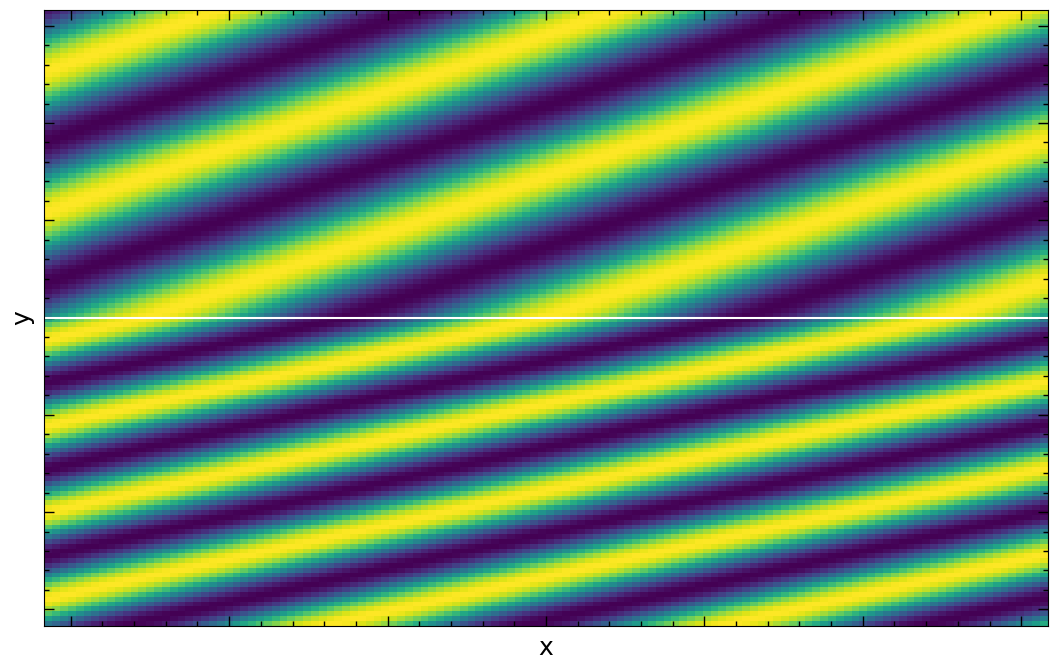

In [3]:
# create a figure containing a single set of axes
fig1, ax1 = plt.subplots(figsize=(8*1.618,8))

ax1.pcolormesh(X1, Y1, Z1, shading='auto', cmap='viridis')
ax1.axhline(y=0, color='white', linewidth=1.5)  # Add horizontal line at y=0

# set the tick mark parameters
ax1.minorticks_on()
ax1.tick_params(which='both',direction="in",width=1)
ax1.tick_params(which='major',length=7)
ax1.tick_params(which='minor',length=3.5)
ax1.xaxis.set_ticks_position('both')
ax1.yaxis.set_ticks_position('both')

# Frame and labels
ax1.set_xlabel("x")
ax1.set_ylabel("y")

# ax1.set_title("Beam Radius vs z")
ax1.set_xticklabels([])  # Hide x-axis tick labels
ax1.set_yticklabels([])  # Hide y-axis tick labels

plt.show()


## Make interactive with `matplotlib` and `ipywidgets`

In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from ipywidgets import interact, FloatSlider

# --- 1. SETUP DATA GRIDS (X1, Y1) ---
# We use 200x200 resolution to keep pcolormesh responsive
N = 200
L = 10.0
x = np.linspace(-L, L, N)
y = np.linspace(-L, L, N)
X1, Y1 = np.meshgrid(x, y)

# Physics Constants
n1 = 1.0          # Air
n2 = 1.5          # Glass
wavelength = 2.0  # Wavelength

def plot_refraction_exact_style(theta_deg):
    # --- 2. CALCULATE PHYSICS (Z1) ---
    theta1 = np.radians(theta_deg)
    
    # Snell's Law: n1*sin(t1) = n2*sin(t2)
    sin_theta2 = (n1 / n2) * np.sin(theta1)
    theta2 = np.arcsin(sin_theta2)
    
    k0 = 2 * np.pi / wavelength
    
    # Region 1 (Top): Incident Wave
    k1x = k0 * n1 * np.sin(theta1)
    k1y = -k0 * n1 * np.cos(theta1)
    phase1 = k1x * X1 + k1y * Y1
    
    # Region 2 (Bottom): Refracted Wave
    k2x = k0 * n2 * np.sin(theta2)
    k2y = -k0 * n2 * np.cos(theta2)
    phase2 = k2x * X1 + k2y * Y1
    
    # Combine fields
    Z1 = np.where(Y1 > 0, np.cos(phase1), np.cos(phase2))

    # --- 3. YOUR EXACT PLOT CODE ---
    # create a figure containing a single set of axes
    fig1, ax1 = plt.subplots(figsize=(8*1.618, 8))

    ax1.pcolormesh(X1, Y1, Z1, shading='auto', cmap='viridis')
    ax1.axhline(y=0, color='white', linewidth=1.5)  # Add horizontal line at y=0

    # set the tick mark parameters
    ax1.minorticks_on()
    ax1.tick_params(which='both', direction="in", width=1)
    ax1.tick_params(which='major', length=7)
    ax1.tick_params(which='minor', length=3.5)
    ax1.xaxis.set_ticks_position('both')
    ax1.yaxis.set_ticks_position('both')

    # Frame and labels
    ax1.set_xlabel("x")
    ax1.set_ylabel("y")
    
    # Added dynamic title so you know the angle
    ax1.set_title(f"Refraction at $\\theta_1 = {theta_deg:.1f}^\\circ$")

    ax1.set_xticklabels([])  # Hide x-axis tick labels
    ax1.set_yticklabels([])  # Hide y-axis tick labels

    plt.show()

# --- 4. INTERACTIVE SLIDER ---
slider = FloatSlider(value=45, min=0, max=85, step=1, 
                     description='Angle', 
                     continuous_update=False)

interact(plot_refraction_exact_style, theta_deg=slider);

### Display animation with javascript from standalone html
[Link to animation](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch02/ch02-04-2D_animation.html)

*Animation.* The pre-rendered animation for this section is shown on the [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch02/ch02-04.html) (direct link: [ch02-04-2D_animation.html](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch02/ch02-04-2D_animation.html)). It is not embedded here because Colab cannot load files from the textbook site; running the code above produces the live version.

## Make 3D plot with `matplotlib`

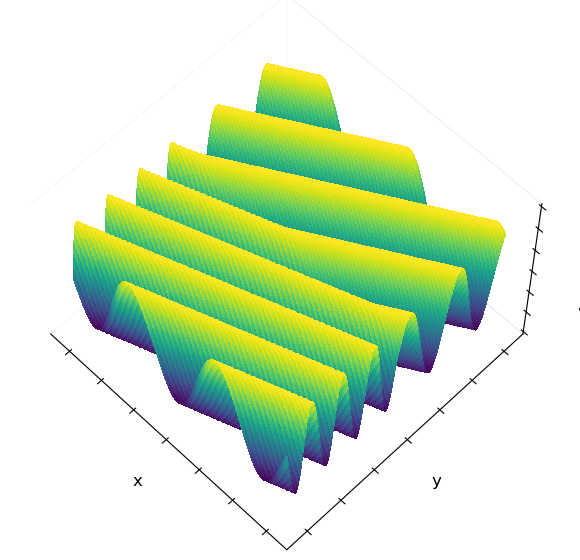

In [6]:
# Enables interactive backend for rotation
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# --- 1. CONFIGURATION ---
font = {'family' : 'sans-serif', 'size' : 12}
plt.rc('font', **font)

# Constants
ni = 1.00
nt = 1.50
omega0 = 1
phi0 = 0
k_mag0 = 5
t0 = 0

# Resolution: 150 for smooth rotation
numpoints1 = 150 

theta_i_deg1 = 30 
theta_i1 = np.radians(theta_i_deg1)
theta_t1 = np.arcsin(ni / nt * np.sin(theta_i1)) 

# Wave vectors
ki1 = ni * np.array([np.sin(theta_i1), -np.cos(theta_i1)]) * k_mag0
kt1 = nt * np.array([np.sin(theta_t1), -np.cos(theta_t1)]) * k_mag0

# -- Wave Grid --
x1 = np.linspace(-np.pi, np.pi, numpoints1)
y1 = np.linspace(-np.pi, np.pi, numpoints1)
X1, Y1 = np.meshgrid(x1, y1)

# Electric fields
def Ei1(x, y, ki):
    return np.real(np.exp(1j * (ki[0] * x + ki[1] * y - omega0*t0 - phi0)))

def Et1(x, y, kt):
    return np.real(np.exp(1j * (kt[0] * x + kt[1] * y - omega0*t0 - phi0)))

Z1 = np.where(Y1 >= 0, Ei1(X1, Y1, ki1), Et1(X1, Y1, kt1))

# --- 2. PLOTTING ---
fig2 = plt.figure(figsize=(9, 7))
ax = fig2.add_subplot(111, projection='3d')

# Hide the "Figure 1" header/footer in the widget view
if hasattr(fig2.canvas, "header_visible"):
    fig2.canvas.header_visible = False
if hasattr(fig2.canvas, "footer_visible"):
    fig2.canvas.footer_visible = False

# Plot the Wave
# rstride=1, cstride=1 for max detail
ax.plot_surface(X1, Y1, Z1, cmap='viridis', 
                linewidth=0, antialiased=False, 
                rstride=1, cstride=1)

# --- 3. STYLING ---
# Frame labels
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("Amplitude")
ax.set_zlim(-1.5, 1.5)

# Tick Parameters (Hiding labels, keeping ticks)
ax.set_xticklabels([])
ax.set_yticklabels([])
ax.set_zticklabels([])

# Remove the gray pane backgrounds
ax.xaxis.pane.fill = False
ax.yaxis.pane.fill = False
ax.zaxis.pane.fill = False

# Remove grid lines
ax.grid(False)

# Initial view angle
ax.view_init(elev=60, azim=-45)

plt.show()

## Animate with `matplotlib`

In [ ]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from ipywidgets import interact, FloatSlider

# --- 1. CONFIGURATION ---
font = {'family' : 'sans-serif', 'size' : 12}
plt.rc('font', **font)

# Constants
ni = 1.00
nt = 1.50
omega0 = 5  # Speed of oscillation
phi0 = 0
k_mag0 = 5

# OPTIMIZATION: Reduced to 100 for smoother animation
numpoints1 = 100 

theta_i_deg1 = 30 
theta_i1 = np.radians(theta_i_deg1)
theta_t1 = np.arcsin(ni / nt * np.sin(theta_i1)) 

# Wave vectors
ki1 = ni * np.array([np.sin(theta_i1), -np.cos(theta_i1)]) * k_mag0
kt1 = nt * np.array([np.sin(theta_t1), -np.cos(theta_t1)]) * k_mag0

# -- Wave Grid --
x1 = np.linspace(-np.pi, np.pi, numpoints1)
y1 = np.linspace(-np.pi, np.pi, numpoints1)
X1, Y1 = np.meshgrid(x1, y1)

# --- 2. SETUP PLOT OBJECTS ---
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection='3d')

# Hide header/footer
if hasattr(fig.canvas, "header_visible"):
    fig.canvas.header_visible = False
if hasattr(fig.canvas, "footer_visible"):
    fig.canvas.footer_visible = False

# Initial View settings
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("Amplitude")
ax.set_zlim(-1.5, 1.5)
ax.set_xticklabels([])
ax.set_yticklabels([])
ax.set_zticklabels([])
ax.xaxis.pane.fill = False
ax.yaxis.pane.fill = False
ax.zaxis.pane.fill = False
ax.grid(False)
ax.view_init(elev=60, azim=-45)

# Global variable to store the surface object
surf = None

def update_wave(t):
    global surf
    
    # Remove previous surface if it exists
    if surf:
        surf.remove()
        
    # --- CALCULATE NEW FIELD ---
    # Phase now includes -omega0 * t
    phase_i = ki1[0] * X1 + ki1[1] * Y1 - omega0 * t - phi0
    phase_t = kt1[0] * X1 + kt1[1] * Y1 - omega0 * t - phi0
    
    Ei = np.real(np.exp(1j * phase_i))
    Et = np.real(np.exp(1j * phase_t))
    
    Z = np.where(Y1 >= 0, Ei, Et)
    
    # --- PLOT NEW SURFACE ---
    # rstride/cstride=1 for quality, but N=100 keeps it fast
    surf = ax.plot_surface(X1, Y1, Z, cmap='viridis', 
                           linewidth=0, antialiased=False, 
                           rstride=1, cstride=1)

# --- 3. CREATE SLIDER ---
slider = FloatSlider(value=0, min=0, max=10, step=0.1, 
                     description='Time', 
                     continuous_update=True) # Update while dragging

interact(update_wave, t=slider);

### Display animation with javascript from standalone html
[Link to animation](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch02/ch02-04-3D_animation.html)

*Animation.* The pre-rendered animation for this section is shown on the [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch02/ch02-04.html) (direct link: [ch02-04-3D_animation.html](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch02/ch02-04-3D_animation.html)). It is not embedded here because Colab cannot load files from the textbook site; running the code above produces the live version.